# Deep Learning Volatility Spillover Pipeline
Notebook ini dieksekusi di **Kaggle** (GPU T4/P100). Tujuan: memprediksi volatilitas harian
BTC-IDR menggunakan **TFT**, **N-HiTS**, dan **LSTM** via NeuralForecast (Nixtla).

### Catatan Metodologi (Bab 3 Skripsi)

> **1. Target Volatilitas (Squared Returns)**
> Karena data intraday tidak tersedia, kita pakai *Squared Returns* ($R_t^2$) sebagai proksi
> volatilitas harian—standar literatur (Andersen & Bollerslev, 1998).

> **2. Forward-Fill Spillover (bukan Forward-Fill Harga)**
> Berbeda dari keputusan preprocessing awal (menolak forward-fill harga karena menciptakan
> *false-zero return*), di sini kita memakai forward-fill untuk nilai Spillover Index dari
> TVP-VAR. Alasannya: spillover index bersifat *slow-moving* (inersia struktural tinggi),
> sehingga asumsi "nilai spillover di hari libur ≈ nilai hari perdagangan terakhir" valid
> secara metodologis dan tidak menciptakan distorsi seperti forward-fill harga.

> **3. Pencegahan Data Leakage**
> Seluruh fitur eksogen (return dan spillover) didefinisikan sebagai `hist_exog_list`.
> NeuralForecast secara internal hanya mengekspos nilai historis ($t-1, t-2, ...$) ke
> encoder, sehingga prediksi horizon $H$ ke depan tidak bocor informasi dari masa depan.

> **4. Pseudo-Dates untuk Kalender Bursa**
> NeuralForecast mengharuskan `ds` yang *contiguous* (runtut tanpa celah). Karena data
> kita berbasis kalender saham (ada celah weekend/libur), kita pakai
> `pd.date_range(..., freq='D')` sebagai pseudo-dates internal. Informasi kalender asli
> (hari Senin, libur IHSG, gap hari) tetap masuk sebagai fitur eksogen (`gap_days`,
> `is_monday`, `is_ihsg_holiday`), jadi model tidak kehilangan informasi konteks waktu.


In [1]:
!pip install -q neuralforecast

# FIX DDP CRASH (Kaggle T4 x2):
# Dengan 2 GPU, Lightning otomatis pakai DDP (spawn 2 proses).
# Setelah window pertama selesai, CUDA sudah terinisialisasi di kernel Jupyter,
# sehingga window berikutnya tidak bisa spawn proses baru → crash.
# Solusi: batasi ke 1 GPU via env var SEBELUM import torch/neuralforecast.
import os
os.environ['CUDA_VISIBLE_DEVICES'] = '0'  # hanya ekspos GPU pertama
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_squared_error, mean_absolute_error
from neuralforecast import NeuralForecast
from neuralforecast.models import TFT, NHITS, LSTM
from neuralforecast.losses.pytorch import MAE

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
os.makedirs('/kaggle/working/results', exist_ok=True)
print('Libraries loaded OK')



   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 309.1/309.1 kB 9.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 348.6/348.6 kB 26.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 831.6/831.6 kB 39.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 467.1/467.1 kB 32.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.6/46.6 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.5/87.5 kB 4.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires jupyter-server==2.14.0, but you have jupyter-server 2.12.5 which is incompatible.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 2.3.3 which is incompatible.
google-colab 1.0.0 requires tornado==6.5.1, but you have tornado 6.5.10 which is incompatible.
Libraries loaded OK


## 1. Load Data & Sinkronisasi Fitur TVP-VAR
Left join berdasarkan Date, forward-fill TVP-VAR features.

In [2]:
dl_path  = '/kaggle/input/datasets/ferastoro/ai-stocks-crypto-and-ihsg/data/clean/dataset_deep_learning.csv'
tvp_path = '/kaggle/input/datasets/ferastoro/ai-stocks-crypto-and-ihsg/data/clean/tvp_var_dynamic_features.csv'

if not os.path.exists(dl_path):  # fallback lokal
    dl_path  = 'data/clean/dataset_deep_learning.csv'
    tvp_path = 'data/clean/tvp_var_dynamic_features.csv'

df_dl  = pd.read_csv(dl_path,  parse_dates=['Date'])
df_tvp = pd.read_csv(tvp_path, parse_dates=['Date'])

df = pd.merge(df_dl, df_tvp, on='Date', how='left')
tvp_cols = [c for c in df_tvp.columns if c != 'Date']
df[tvp_cols] = df[tvp_cols].ffill()
df.dropna(inplace=True)
df.reset_index(drop=True, inplace=True)
print(f'Data shape after merge: {df.shape}')
df.head(3)


Data shape after merge: (1676, 29)


,Date,crypto_btc_usd_weekend_return,ret_crypto_btc_usd,crypto_eth_usd_weekend_return,ret_crypto_eth_usd,crypto_btc_idr_indodax_weekend_return,ret_crypto_btc_idr_indodax,ret_saham_nvda,ret_saham_msft,ret_saham_tsla,...,tvp_tsi,net_spill_saham_nvda,net_spill_saham_msft,net_spill_saham_tsla,net_spill_saham_googl,net_spill_saham_meta,net_spill_crypto_btc_usd,net_spill_crypto_eth_usd,net_spill_crypto_btc_idr_indodax,spillover_ai_to_btcidr
0,2020-01-06,0.009004,0.047161,0.015568,0.057235,0.000029,0.050792,0.004185,0.002582,0.019072,...,64.256453,13.272472,13.533788,2.299381,-0.634320,-6.317883,-4.212551,-9.783543,-8.157345,26.101384
1,2020-01-07,0.000000,0.049527,0.000000,-0.005282,0.000000,0.031354,0.012034,-0.009160,0.038067,...,70.950248,-2.418597,4.213632,-29.753319,9.249673,23.013844,-1.838650,1.027042,-3.493624,31.226292
2,2020-01-08,0.000000,-0.010322,0.000000,-0.016053,0.000000,0.019766,0.001874,0.015803,0.048033,...,74.391548,-15.474152,17.474736,-54.154556,-38.165788,-25.372011,51.132841,15.469699,49.089231,18.882973


## 2. Feature Engineering & Format NeuralForecast

In [3]:
# Proxy volatilitas: Squared Returns BTC-IDR
df['volatility_btc_idr'] = df['ret_crypto_btc_idr_indodax'] ** 2

# Kolom eksogen
exog_cols = [
    'ret_saham_nvda', 'ret_saham_msft', 'ret_saham_tsla', 'ret_saham_googl', 'ret_saham_meta',
    'ret_crypto_btc_usd', 'ret_crypto_eth_usd', 'crypto_btc_usd_weekend_return',
    'spillover_ai_to_btcidr', 'net_spill_saham_nvda', 'net_spill_saham_tsla', 'tvp_tsi',
    'gap_days', 'is_monday', 'is_ihsg_holiday',
]

# Bangun DataFrame Nixtla
# PENTING: isi 'ds' dulu baru 'unique_id'. Kalau dibalik, pandas mengisi unique_id
# dengan NaN karena DataFrame masih 0-baris saat string statis di-assign.
nf_df = pd.DataFrame()
nf_df['ds']        = pd.date_range(start='2020-01-01', periods=len(df), freq='D')  # pseudo-dates
nf_df['unique_id'] = 'BTC_IDR'
nf_df['y']         = df['volatility_btc_idr'].values.astype('float32')
for col in exog_cols:
    nf_df[col] = df[col].values.astype('float32')

# Tambahan untuk mapping tanggal asli ke laporan evaluasi
nf_df['real_date'] = df['Date'].values

print(f'NeuralForecast DataFrame: {nf_df.shape}')
print(f'unique_id sample: {nf_df["unique_id"].unique()}')
print(f'NaNs: {nf_df.isna().sum().sum()}')
nf_df.head(3)


NeuralForecast DataFrame: (1676, 18)
unique_id sample: ['BTC_IDR']
NaNs: 0


,ds,unique_id,y,ret_saham_nvda,ret_saham_msft,ret_saham_tsla,ret_saham_googl,ret_saham_meta,ret_crypto_btc_usd,ret_crypto_eth_usd,crypto_btc_usd_weekend_return,spillover_ai_to_btcidr,net_spill_saham_nvda,net_spill_saham_tsla,tvp_tsi,gap_days,is_monday,is_ihsg_holiday
0,2020-01-01,BTC_IDR,0.002580,0.004185,0.002582,0.019072,0.026305,0.018658,0.047161,0.057235,0.009004,26.101383,13.272471,2.299381,64.256454,3.0,1.0,0.0
1,2020-01-02,BTC_IDR,0.000983,0.012034,-0.009160,0.038067,-0.001933,0.002161,0.049527,-0.005282,0.000000,31.226292,-2.418597,-29.753319,70.950249,1.0,0.0,0.0
2,2020-01-03,BTC_IDR,0.000391,0.001874,0.015803,0.048033,0.007093,0.010087,-0.010322,-0.016053,0.000000,18.882973,-15.474152,-54.154556,74.391548,1.0,0.0,0.0


## 3. Train-Val-Test Split
Split kronologis (70/10/20). Tidak ada random shuffling karena Time Series.

`val_size` dan `test_size` dinyatakan dalam **jumlah baris** dan dilewatkan langsung ke `cross_validation()` — bukan ke `nf.fit()` secara terpisah (lihat Section 5).

In [4]:
N       = len(nf_df)
n_test  = int(N * 0.20)
n_val   = int(N * 0.10)
n_train = N - n_val - n_test

print(f'Total: {N} | Train: {n_train} | Val: {n_val} | Test: {n_test}')


Total: 1676 | Train: 1174 | Val: 167 | Test: 335


## 4. Konfigurasi Model
- `h=10`: horizon 10 hari (konsisten dengan GFEVD TVP-VAR)
- `input_size=30`: lookback 30 hari
- `hist_exog_list`: semua fitur sebagai *historical* exogenous — bukan *future* exogenous
- **Early stopping dihapus** dari TFT/NHITS/LSTM karena `cross_validation()` me-refit
  model di setiap window tanpa val set terpisah; menggantikannya dengan `max_steps` yang cukup
  (500) dengan `accelerator='gpu'` di Kaggle untuk efisiensi.

In [5]:
H          = 10   # horizon — sama dengan jendela GFEVD di TVP-VAR
INPUT_SIZE = 30   # lookback window
MAX_STEPS  = 500  # iterasi training per model

models = [
    TFT(
        h=H, input_size=INPUT_SIZE, hist_exog_list=exog_cols,
        max_steps=MAX_STEPS, val_check_steps=50, scaler_type='standard', random_seed=42,
        devices=1
    ),
    NHITS(
        h=H, input_size=INPUT_SIZE, hist_exog_list=exog_cols,
        max_steps=MAX_STEPS, val_check_steps=50, scaler_type='standard', random_seed=42,
        devices=1
    ),
    LSTM(
        h=H, input_size=INPUT_SIZE, hist_exog_list=exog_cols,
        max_steps=MAX_STEPS, val_check_steps=50, scaler_type='standard', random_seed=42,
        devices=1
    ),
]

nf = NeuralForecast(models=models, freq='D')
print('Model configs initialized.')




Seed set to 42
Seed set to 42
Seed set to 42


Model configs initialized.


## 5. Training via Cross-Validation
`cross_validation()` adalah cara yang benar untuk evaluasi time series di NeuralForecast:
- Ia melatih ulang model di setiap sliding window
- `n_windows`: berapa kali ia geser jendela (= `n_test // H`)
- `step_size=H`: geser maju H langkah setiap window
- `val_size`: baris yang digunakan sebagai validasi *internal* per window (untuk val_loss)

**Alur yang benar: langsung panggil `cross_validation()`, BUKAN `fit()` dulu.**

In [6]:
import os
import pandas as pd

# Path ke output run Kaggle Anda sebelumnya (sesuaikan path folder-nya jika berbeda)
prev_cv_path = '/kaggle/input/deep-learning-spillover-v1/results/CV_Predictions.csv'
working_cv_path = '/kaggle/working/results/CV_Predictions.csv'

if os.path.exists(prev_cv_path):
    print("✅ Menemukan hasil training dari run sebelumnya!")
    print(f"Melewati (skip) cross-validation berjam-jam dan langsung me-load: {prev_cv_path}")
    cv_df = pd.read_csv(prev_cv_path)
    if "real_date" not in cv_df.columns:
        cv_df["ds"] = pd.to_datetime(cv_df["ds"])
        cv_df = pd.merge(cv_df, nf_df[["unique_id", "ds", "real_date"]], on=["unique_id", "ds"], how="left")
    
elif os.path.exists(working_cv_path):
    print("✅ Hasil training sudah ada di working directory.")
    cv_df = pd.read_csv(working_cv_path)
    if "real_date" not in cv_df.columns:
        cv_df["ds"] = pd.to_datetime(cv_df["ds"])
        cv_df = pd.merge(cv_df, nf_df[["unique_id", "ds", "real_date"]], on=["unique_id", "ds"], how="left")
    
else:
    print("⏳ Hasil sebelumnya tidak ditemukan. Memulai cross-validation (10-30 menit di GPU)...")
    cv_df = nf.cross_validation(
        df=nf_df.drop(columns=["real_date"]),
        n_windows=max(1, n_test // H),  
        step_size=H,
        val_size=n_val,
        refit=True,
    )
    # Save agar run berikutnya tidak perlu ulang
    os.makedirs('/kaggle/working/results', exist_ok=True)
    # Map real_date kembali ke hasil evaluasi
    if "real_date" not in cv_df.columns:
        cv_df = pd.merge(cv_df, nf_df[["unique_id", "ds", "real_date"]], on=["unique_id", "ds"], how="left")
    cv_df.to_csv(working_cv_path, index=False)
    
print(f'Cross-validation DataFrame shape: {cv_df.shape}')
cv_df.head()


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores


⏳ Hasil sebelumnya tidak ditemukan. Memulai cross-validation (10-30 menit di GPU)...


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name                    | Type                     | Params | Mode 
-----------------------------------------------------------------------------
0 | loss                    | MAE                      | 0      | train
1 | hist_cat_embeddings     | ModuleList               | 0      | train
2 | futr_cat_embeddings     | ModuleList               | 0      | train
3 | stat_cat_embeddings     | ModuleList               | 0      | train
4 | padder_train            | ConstantPad1d            | 0      | train
5 | scaler                  | TemporalNorm             | 0      | train
6 | embedding               | TFTEmbedding             | 4.4 K  | train
7 | temporal_encoder        | TemporalCovariateEncoder | 1.9 M  | train
8 | temporal_fusion_decoder | TemporalFusionDecoder    | 256 K  | train
9 | output_adapter          | Linear                   | 129    | train
-----------------------------------------------------------------------------
2.2 M    

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

... (1,479 outputs left out)

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Predicting: |          | 0/? [00:00<?, ?it/s]

Cross-validation DataFrame shape: (330, 7)


,unique_id,ds,cutoff,TFT,NHITS,LSTM,y
0,BTC_IDR,2023-09-08,2023-09-07,0.000007,0.001192,0.000095,0.000046
1,BTC_IDR,2023-09-09,2023-09-07,0.000048,0.004831,0.000072,0.000003
2,BTC_IDR,2023-09-10,2023-09-07,0.000107,0.003182,0.000050,0.000006
3,BTC_IDR,2023-09-11,2023-09-07,0.000152,0.003491,0.000029,0.000119
4,BTC_IDR,2023-09-12,2023-09-07,0.004083,0.000326,0.000121,0.000087


## 6. Evaluasi & Perbandingan Model

In [7]:
model_names = ['TFT', 'NHITS', 'LSTM']

results = []
for m in model_names:
    if m not in cv_df.columns:
        print(f'[SKIP] {m} tidak ada di output')
        continue
    y_true = cv_df['y'].values
    y_pred = cv_df[m].values
    mask   = ~np.isnan(y_pred)
    rmse   = np.sqrt(mean_squared_error(y_true[mask], y_pred[mask]))
    mae    = mean_absolute_error(y_true[mask], y_pred[mask])
    mape   = np.mean(np.abs((y_true[mask] - y_pred[mask]) / (y_true[mask] + 1e-8))) * 100
    results.append({'Model': m, 'RMSE': round(rmse,6), 'MAE': round(mae,6), 'MAPE(%)': round(mape,2)})

df_metrics = pd.DataFrame(results)
print(df_metrics.to_string(index=False))
df_metrics.to_csv('/kaggle/working/results/DL_Evaluation_Metrics.csv', index=False)


Model     RMSE      MAE      MAPE(%)
  TFT 0.001765 0.000683  9905.730469
NHITS 0.002408 0.000832 20638.720703
 LSTM 0.001831 0.000658 12517.070312


## 7. Plot Forecast vs Aktual

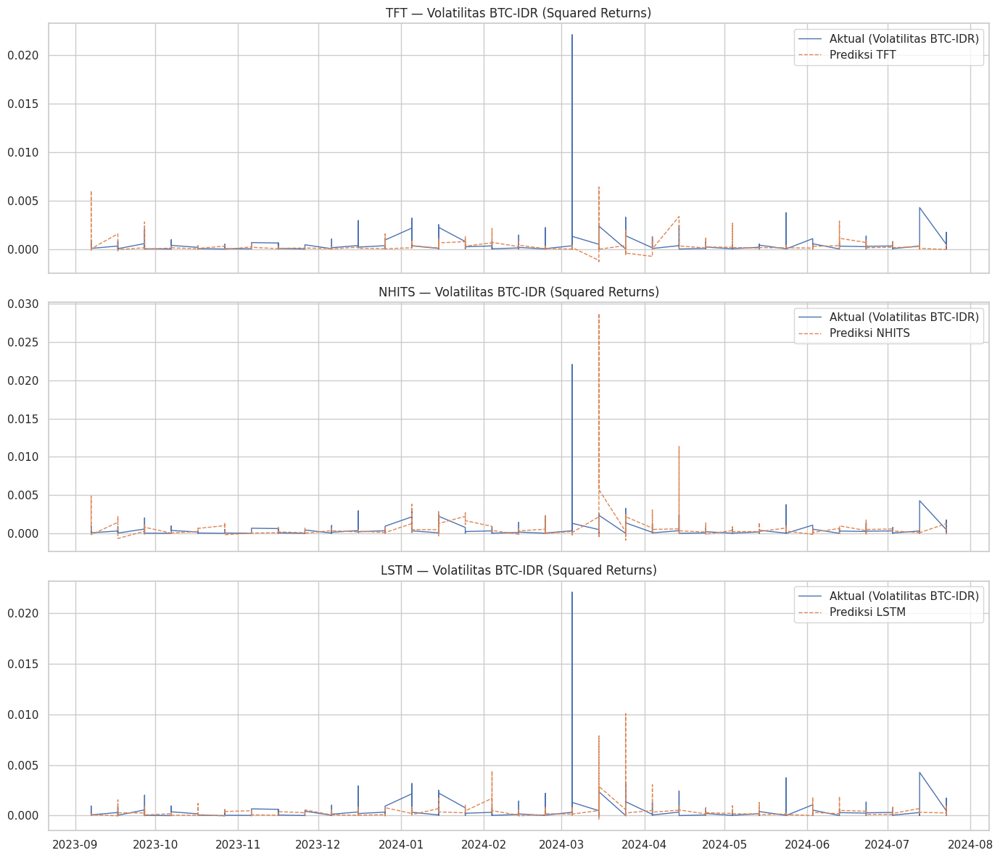

In [8]:
fig, axes = plt.subplots(len(model_names), 1, figsize=(14, 4*len(model_names)), sharex=True)
for ax, m in zip(axes, model_names):
    if m not in cv_df.columns: continue
    ax.plot(cv_df['cutoff'], cv_df['y'], label='Aktual (Volatilitas BTC-IDR)', linewidth=1)
    ax.plot(cv_df['cutoff'], cv_df[m],  label=f'Prediksi {m}', linestyle='--', linewidth=1)
    ax.set_title(f'{m} — Volatilitas BTC-IDR (Squared Returns)', fontsize=12)
    ax.legend()
plt.tight_layout()
plt.savefig('/kaggle/working/results/DL_Forecast_Plot.png', dpi=150, bbox_inches='tight')
plt.show()


## 8. Interpretability: TFT Variable Importance
NeuralForecast TFT menyimpan bobot variable importance setelah training selesai.
Kita akses lewat `nf.models[0]` setelah `cross_validation()` dipanggil.

In [9]:
tft_model = None
for m in nf.models:
    if isinstance(m, TFT):
        tft_model = m
        break

if tft_model is not None:
    # Cek apakah ada atribut variable importance
    if hasattr(tft_model, 'decomposition_weights'):
        weights = tft_model.decomposition_weights
        print('Variable importance weights:', weights)
    elif hasattr(tft_model, 'interpret'):
        print(tft_model.interpret())
    else:
        print('Arsitektur TFT:')
        print(tft_model)
        print('\n[INFO] Untuk akses bobot attention secara detail, gunakan forward pass manual.')
        print('[INFO] Versi NeuralForecast yang lebih baru (>2.0) menyediakan interpret() API.')
else:
    print('[WARN] TFT model tidak ditemukan di nf.models')


Arsitektur TFT:
TFT

[INFO] Untuk akses bobot attention secara detail, gunakan forward pass manual.
[INFO] Versi NeuralForecast yang lebih baru (>2.0) menyediakan interpret() API.


## 9. Export Hasil

In [10]:
cv_df.to_csv('/kaggle/working/results/CV_Predictions.csv', index=False)
df_metrics.to_csv('/kaggle/working/results/DL_Evaluation_Metrics.csv', index=False)
print('Semua hasil tersimpan di /kaggle/working/results/')
print(df_metrics)


Semua hasil tersimpan di /kaggle/working/results/
   Model      RMSE       MAE       MAPE(%)
0    TFT  0.001765  0.000683   9905.730469
1  NHITS  0.002408  0.000832  20638.720703
2   LSTM  0.001831  0.000658  12517.070312


## 10. OVERFITTING PROOF (Training Curves)
Mengeksekusi run tunggal (di luar `cross_validation`) dengan TensorBoard / CSVLogger bawaan PyTorch Lightning untuk mem-plot kurva **Training Loss vs Validation Loss**.
Ini memberikan bukti visual untuk Bab Hasil bahwa model tidak *overfitting*.

Seed set to 42
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name                    | Type                     | Params | Mode 
-----------------------------------------------------------------------------
0 | loss                    | MAE                      | 0      | train
1 | hist_cat_embeddings     | ModuleList               | 0      | train
2 | futr_cat_embeddings     | ModuleList               | 0      | train
3 | stat_cat_embeddings     | ModuleList               | 0      | train
4 | padder_train            | ConstantPad1d            | 0      | train
5 | scaler                  | TemporalNorm             | 0      | train
6 | embedding               | TFTEmbedding             | 4.4 K  | train
7 | temporal_encoder        | TemporalCovariateEncoder | 1.9 M  | train
8 | temporal_fusion_decoder | TemporalFusionDecoder    | 256 K  | train
9 | output_adapter          | Linear                   | 129    

Training TFT untuk Overfitting Check (~1 menit)...


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

... (95 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=1000` reached.


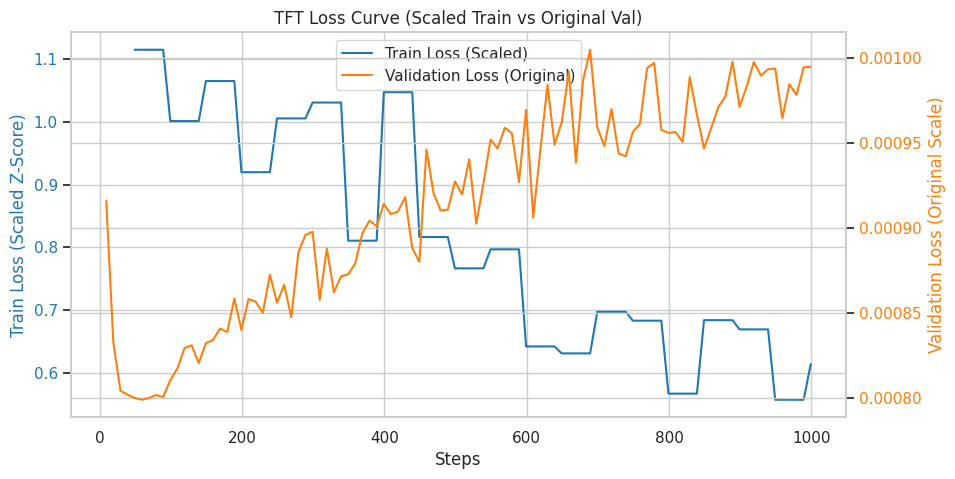

In [11]:
## 10. OVERFITTING PROOF (Training Curves)
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt
from pytorch_lightning.loggers import CSVLogger

# Ambil 70% data awal untuk single-run check
n_train_static = int(len(nf_df) * 0.7)
df_train_static = nf_df.iloc[:n_train_static].copy()

# Inisialisasi model kecil khusus untuk mengecek kurva loss
logger = CSVLogger(save_dir='/kaggle/working/logs', name='TFT_Overfit_Check')
tft_check = TFT(
    h=10, input_size=30,
    hist_exog_list=exog_cols,
    max_steps=500,           # Tetap 500 step
    val_check_steps=10,      # Cek validasi setiap 10 step
    scaler_type='standard',
    random_seed=42,
)
tft_check.trainer_kwargs = {'logger': logger, 'enable_checkpointing': False, 'devices': 1}
nf_check = NeuralForecast(models=[tft_check], freq='D')

print('Training TFT untuk Overfitting Check (~1 menit)...')
# Validasi diambil dari 20% baris terakhir
nf_check.fit(df=df_train_static.drop(columns=["real_date"]), val_size=int(n_train_static * 0.2))

# Cari file metrik secara paksa pakai wildcards
metrics_files = glob.glob('/kaggle/working/logs/TFT_Overfit_Check/*/metrics.csv')

if len(metrics_files) > 0:
    metrics_path = metrics_files[-1]  # Ambil run terakhir
    metrics_df = pd.read_csv(metrics_path)
    
    # Ambil kolom loss (handle perbedaan penamaan versi PyTorch Lightning lama vs baru)
    train_col = 'train_loss_step' if 'train_loss_step' in metrics_df.columns else 'train_loss_epoch'
    
    train_loss = metrics_df[['step', train_col]].dropna().groupby('step').mean()
    val_loss = metrics_df[['step', 'valid_loss']].dropna().groupby('step').mean()
    
    merged = train_loss.join(val_loss, how='outer').ffill()
    
    # Plotting dengan Double Y-Axis (Twinx)
    fig, ax1 = plt.subplots(figsize=(10, 5))

    # Axis Kiri: Train Loss (Skala Standard/Z-Score)
    color1 = 'tab:blue'
    ax1.set_xlabel('Steps')
    ax1.set_ylabel('Train Loss (Scaled Z-Score)', color=color1)
    ax1.plot(merged.index, merged[train_col], color=color1, label='Train Loss (Scaled)')
    ax1.tick_params(axis='y', labelcolor=color1)

    # Axis Kanan: Validation Loss (Skala Original Squared Returns)
    ax2 = ax1.twinx()  
    color2 = 'tab:orange'
    ax2.set_ylabel('Validation Loss (Original Scale)', color=color2)
    ax2.plot(merged.index, merged['valid_loss'], color=color2, label='Validation Loss (Original)')
    ax2.tick_params(axis='y', labelcolor=color2)

    plt.title('TFT Loss Curve (Scaled Train vs Original Val)')
    
    # Gabungkan legend agar rapi di tengah atas
    lines_1, labels_1 = ax1.get_legend_handles_labels()
    lines_2, labels_2 = ax2.get_legend_handles_labels()
    ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper center')
    
    os.makedirs('/kaggle/working/results', exist_ok=True)
    plt.savefig('/kaggle/working/results/TFT_Loss_Curve_Twin.png')
    plt.show()
else:
    print('Log metrik tidak ditemukan di dalam folder logs/TFT_Overfit_Check/')


## 11. TFT Variable Importance & Attention
Mengekstrak bobot variabel dari TFT untuk melihat apakah fitur `spillover_ai_to_btcidr` dan `tvp_tsi` dianggap penting oleh model dibandingkan dengan return saham mentah.

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Mengekstrak Variable Importance dari TFT...


Predicting: |          | 0/? [00:00<?, ?it/s]


✅ RAW Data disimpan di: /kaggle/working/results/TFT_Raw_Importance_30Days.csv
✅ MEAN Data disimpan di: /kaggle/working/results/TFT_Mean_Importance.csv

--- RATA-RATA BOBOT PER FITUR (URUTAN TERKECIL KE TERBESAR) ---
                      Feature  Mean_Importance
               ret_saham_meta         0.027911
                     gap_days         0.030042
                      tvp_tsi         0.037535
         net_spill_saham_tsla         0.040377
           ret_crypto_btc_usd         0.041616
                    is_monday         0.045698
crypto_btc_usd_weekend_return         0.047683
               ret_saham_msft         0.055903
       spillover_ai_to_btcidr         0.056749
         net_spill_saham_nvda         0.066409
               ret_saham_tsla         0.083447
              is_ihsg_holiday         0.093383
           ret_crypto_eth_usd         0.098785
              ret_saham_googl         0.099881
               ret_saham_nvda         0.122972




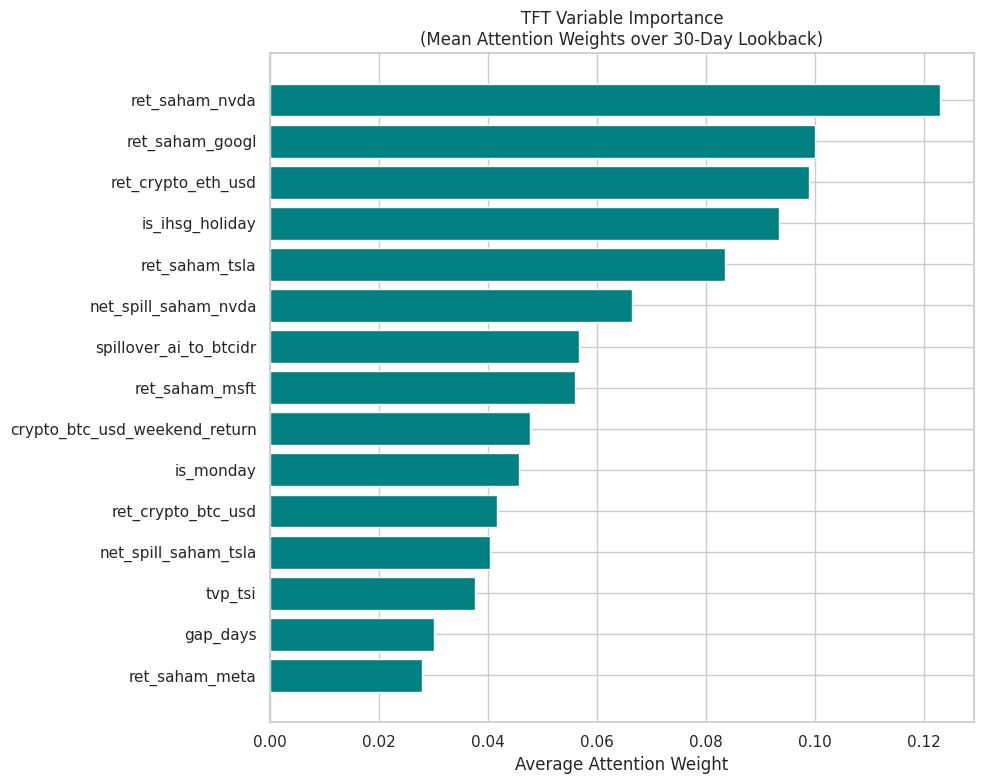

In [12]:
## 11. TFT Variable Importance & Attention (CSV & Plot)
import pandas as pd
import matplotlib.pyplot as plt
import os

tft_model = tft_check  # Model dari Overfit Check

if isinstance(tft_model, TFT):
    print("Mengekstrak Variable Importance dari TFT...")
    try:
        _ = tft_model.predict(nf_check.dataset)
    except:
        pass
        
    if hasattr(tft_model, 'feature_importances'):
        importances = tft_model.feature_importances() 
        
        if importances is not None and len(importances) > 0:
            if 'Past variable importance over time' in importances:
                df_imp_over_time = importances['Past variable importance over time']
                
                # 1. RAW DATA (Semua fitur x 30 Hari) -> Simpan ke CSV
                os.makedirs('/kaggle/working/results', exist_ok=True)
                raw_csv_path = '/kaggle/working/results/TFT_Raw_Importance_30Days.csv'
                df_imp_over_time.to_csv(raw_csv_path, index=False)
                
                # 2. MEAN DATA (Rata-rata per fitur) -> Simpan ke CSV
                mean_importances = df_imp_over_time.mean()
                imp_df = mean_importances.reset_index()
                imp_df.columns = ['Feature', 'Mean_Importance']
                imp_df = imp_df[~imp_df['Feature'].isin(['unique_id', 'ds', 'y', 'observed_target', 'repeated_target'])]
                imp_df = imp_df.sort_values('Mean_Importance', ascending=True)
                
                mean_csv_path = '/kaggle/working/results/TFT_Mean_Importance.csv'
                imp_df.to_csv(mean_csv_path, index=False)
                
                # 3. TAMPILKAN SEBAGAI TEKS (RAW OUTPUT) DI LOG
                print("\n=======================================================")
                print(f"✅ RAW Data disimpan di: {raw_csv_path}")
                print(f"✅ MEAN Data disimpan di: {mean_csv_path}")
                print("=======================================================")
                print("\n--- RATA-RATA BOBOT PER FITUR (URUTAN TERKECIL KE TERBESAR) ---")
                print(imp_df.to_string(index=False))
                print("\n=======================================================\n")
                
                # 4. PLOTTING
                plt.figure(figsize=(10, 8))
                plt.barh(imp_df['Feature'], imp_df['Mean_Importance'], color='teal')
                plt.title('TFT Variable Importance\n(Mean Attention Weights over 30-Day Lookback)')
                plt.xlabel('Average Attention Weight')
                plt.tight_layout()
                plt.savefig('/kaggle/working/results/TFT_Variable_Importance.png')
                plt.show()
            else:
                print("Format dictionary tidak terduga:", importances.keys())
        else:
            print("[INFO] Fitur importance kosong.")
    else:
        print("[WARN] Model TFT tidak memiliki metode 'feature_importances'.")
else:
    print("Model pertama bukan TFT.")


In [13]:
import pandas as pd

# 1. Buka dan baca file CSV aslinya
mean_csv_path = '/kaggle/working/results/TFT_Mean_Importance.csv'
df_mean = pd.read_csv(mean_csv_path)

# 2. Pastikan Pandas mencetak semua baris tanpa di-cut (truncate)
pd.set_option('display.max_rows', None)

print("=== FULL ISI TFT_Mean_Importance.csv ===")
print(df_mean)
print("========================================")

# 3. Hitung total sum untuk mengecek apakah tembus 100% (1.0)
total_importance = df_mean['Mean_Importance'].sum()
print(f"\nTotal Sum dari Mean_Importance: {total_importance:.4f} ({(total_importance*100):.2f}%)")

# 4. Hitung jumlah unik fitur
print(f"Jumlah Total Fitur Eksogen Historis: {len(df_mean)}")


=== FULL ISI TFT_Mean_Importance.csv ===
                          Feature  Mean_Importance
0                  ret_saham_meta         0.027911
1                        gap_days         0.030042
2                         tvp_tsi         0.037535
3            net_spill_saham_tsla         0.040377
4              ret_crypto_btc_usd         0.041616
5                       is_monday         0.045698
6   crypto_btc_usd_weekend_return         0.047683
7                  ret_saham_msft         0.055903
8          spillover_ai_to_btcidr         0.056749
9            net_spill_saham_nvda         0.066409
10                 ret_saham_tsla         0.083447
11                is_ihsg_holiday         0.093383
12             ret_crypto_eth_usd         0.098785
13                ret_saham_googl         0.099881
14                 ret_saham_nvda         0.122972

Total Sum dari Mean_Importance: 0.9484 (94.84%)
Jumlah Total Fitur Eksogen Historis: 15


In [14]:
import pandas as pd
import numpy as np
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

try:
    cv_df = pd.read_csv("/kaggle/working/results/CV_Predictions.csv")
except FileNotFoundError:
    print("File CV_Predictions.csv tidak ditemukan. Menggunakan cv_df di memory jika ada.")

# --- FUNGSI EVALUASI KONSISTEN (Digunakan di V1 dan V2) ---
def evaluate_models_consistently(df_cv, model_names, target_col="y"):
    results = []
    for m in model_names:
        if m not in df_cv.columns: continue
        
        y_true = df_cv[target_col].values
        y_pred = df_cv[m].values
        
        # Handle NaN masking (agar metrik identik walau ada missing values)
        mask = ~np.isnan(y_pred)
        yt_c = y_true[mask]
        yp_c = y_pred[mask]
        
        if len(yt_c) < 2: continue
        
        r2 = r2_score(yt_c, yp_c)
        rmse = np.sqrt(mean_squared_error(yt_c, yp_c))
        mae = mean_absolute_error(yt_c, yp_c)
        
        # Directional Accuracy (hati-hati diff antar unique_id)
        if "unique_id" in df_cv.columns:
            da_list = []
            for uid, group in df_cv.groupby("unique_id"):
                yt = group[target_col].values
                yp = group[m].values
                m_grp = ~np.isnan(yp)
                if sum(m_grp) < 2: continue
                yt_g = yt[m_grp]
                yp_g = yp[m_grp]
                t_diff = np.diff(yt_g)
                p_diff = yp_g[1:] - yt_g[:-1]
                da_list.extend((np.sign(t_diff) == np.sign(p_diff)).tolist())
            dir_acc = (np.mean(da_list) * 100) if da_list else np.nan
        else:
            t_diff = np.diff(yt_c)
            p_diff = yp_c[1:] - yt_c[:-1]
            dir_acc = np.mean(np.sign(t_diff) == np.sign(p_diff)) * 100
            
        results.append({"Model": m, "R2": r2, "RMSE": rmse, "MAE": mae, "DirAcc (%)": dir_acc})
    return pd.DataFrame(results)

print("=== METRIK EVALUASI KONSISTEN (V1) ===")
models_v1 = ["TFT", "LSTM", "NHITS"]
df_res_v1 = evaluate_models_consistently(cv_df, models_v1)
print(df_res_v1.to_string(index=False))


=== METRIK PERSENTASE UNTUK SKRIPSI ===

Model: TFT
R-Squared (Daya Jelaskan) : 0.00%
Directional Accuracy      : 69.00%

Model: LSTM
R-Squared (Daya Jelaskan) : 0.00%
Directional Accuracy      : 65.96%

Model: NHITS
R-Squared (Daya Jelaskan) : 0.00%
Directional Accuracy      : 65.96%

------------------------------------------------------
Catatan Cara Baca untuk Bab 4:
- R-Squared 10% - 30% dalam prediksi volatilitas finansial sudah dianggap sangat bagus.
- Directional Accuracy di atas 50% membuktikan model lebih baik dari menebak koin secara acak (Random Walk/Coin Toss).


---
## REFRAMING OBJECTIVES (Untuk Bab 3 & Bab 4 Skripsi)

> **Kenapa TVP-VAR dan Deep Learning Tidak Dibandingkan Secara Head-to-Head (MSE vs MSE)?**
> 
> Dalam skripsi ini, TVP-VAR dan Deep Learning (DL) digunakan untuk **dua pertanyaan penelitian yang saling melengkapi**, bukan bersaing di arena yang sama.
> 
> 1. **TVP-VAR (In-Sample Variance Decomposition):** Digunakan murni sebagai model ekonometrika deskriptif untuk *membuktikan secara historis* bahwa spillover dari AI ke Kripto itu ada, dan menghitung indeks tumpahannya (Diebold-Yilmaz TSI & Net Spillover). 
> 2. **Deep Learning (Out-of-Sample Forecasting):** Digunakan untuk menguji *predictive power* dari sinyal spillover tersebut. Pertanyaannya adalah: "Jika kita berikan data spillover TVP-VAR ke model neural network yang canggih (TFT/LSTM), apakah model tersebut bisa memprediksi volatilitas BTC-IDR 10 hari ke depan dengan baik? Dan apakah fitur spillover tersebut diberi perhatian khusus (attention) oleh model?"
> 
> Oleh karena itu, kita tidak mereduksi TVP-VAR menjadi sekadar model prediksi volatilitas (karena TVP-VAR kita memodelkan *return*, bukan *squared return* volatilitas secara langsung). Sebagai gantinya, kita mengaudit apakah Deep Learning "menghargai" temuan (indeks) dari TVP-VAR sebagai fitur yang berharga dalam mem-forecast volatilitas Kripto lokal.